# آمار بازده طلا: دم‌های پهن و خوشه‌ای شدن نوسان

**آموزشی است و توصیه سرمایه‌گذاری نیست.** این نوت‌بوک قیمت را پیش‌بینی نمی‌کند. فقط می‌پرسد: بازده روزانه طلا چه شکلی دارد، و آیا شبیه توزیع نرمال است؟

دو چیز را اندازه می‌گیریم:

1. **دم‌های پهن:** روزهای خیلی بزرگ (مثلاً بیش از ۴ انحراف معیار) در واقعیت چند برابر مدل نرمال اتفاق می‌افتند؟
2. **خوشه‌ای شدن نوسان:** آیا بعد از یک روز پرنوسان، روز پرنوسان دیگری محتمل‌تر است؟

**داده:** قیمت اونس طلا از TGJU (غیررسمی). برای ۲۰۰۰ به بعد آن را با آتی COMEX از Yahoo مقایسه کرده‌ایم (در نوت‌بوک ۱). قبل از آن فقط یک منبع داریم و برای هر روز فقط یک قیمت (نه باز و بسته)، پس تحلیل اصلی از سپتامبر ۲۰۰۰ شروع می‌شود و ۱۹۸۰ تا ۱۹۹۹ فقط در پایان به‌عنوان مقایسه می‌آید.

In [1]:
import json, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path("..") if Path("../scripts/fetch_data.py").exists() else Path(".")  # repo checkout or Colab
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)
(ROOT / "images").mkdir(exist_ok=True)

def load_ons():
    f = DATA / "ons_usd.csv"
    if not f.exists():  # data is not stored in the repository
        url = "https://api.tgju.org/v1/market/indicator/summary-table-data/ons"
        rows = json.load(urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"}), timeout=60))["data"]
        num = lambda t: float(t.replace(",", ""))
        pd.DataFrame([(r[6].replace("/", "-"), *map(num, r[:4])) for r in rows],
                     columns=["date", "open", "low", "high", "close"]).sort_values("date").to_csv(f, index=False)
    return pd.read_csv(f, parse_dates=["date"]).set_index("date")["close"]

ons = load_ons()
r_all = np.log(ons).diff().dropna()          # daily log returns, all history
START = "2000-09-01"                          # from here we have a second source
r = r_all[START:]
print(f"{len(ons)} prices, {ons.index[0].date()} to {ons.index[-1].date()}; main sample: {len(r)} returns from {r.index[0].date()}")

12168 prices, 1979-12-26 to 2026-10-16; main sample: 6830 returns from 2000-09-01


## ۱. شکل بازده‌ها

بازده لگاریتمی روزانه را حساب کردیم (`log(P_t / P_{t-1})`). اول عددهای ساده:

In [2]:
print(f"annualised mean : {r.mean() * 252:7.2%}")
print(f"annualised vol  : {r.std() * np.sqrt(252):7.2%}")
print(f"skewness        : {stats.skew(r):7.2f}")
print(f"excess kurtosis : {stats.kurtosis(r):7.2f}   (0 for a normal distribution)")
print("worst days:", {d.date().isoformat(): round(v, 3) for d, v in r.nsmallest(3).items()})
print("best days :", {d.date().isoformat(): round(v, 3) for d, v in r.nlargest(3).items()})

annualised mean :   9.99%
annualised vol  :  17.16%
skewness        :   -0.40
excess kurtosis :    6.26   (0 for a normal distribution)
worst days: {'2026-01-30': -0.103, '2013-04-15': -0.089, '2006-06-13': -0.073}
best days : {'2008-09-17': 0.104, '2008-11-21': 0.069, '2001-09-11': 0.06}


**کشیدگی اضافه (excess kurtosis)** برای توزیع نرمال صفر است. اینجا حدود ۶ است، یعنی دم‌ها خیلی پهن‌ترند.

### چند برابر مدل نرمال؟
روزهایی را می‌شماریم که بازده بیش از ۳، ۴ یا ۵ انحراف معیار از میانگین فاصله دارد و با تعداد مورد انتظار در توزیع نرمال مقایسه می‌کنیم:

In [3]:
z = (r - r.mean()) / r.std()
rows = []
for k in (3, 4, 5):
    expected = 2 * stats.norm.sf(k) * len(z)
    rows.append({"threshold": f"{k} sigma", "observed days": int((z.abs() > k).sum()), "expected if normal": round(expected, 2)})
pd.DataFrame(rows).set_index("threshold")

,observed days,expected if normal
threshold,,
3 sigma,91,18.44
4 sigma,28,0.43
5 sigma,15,0.00


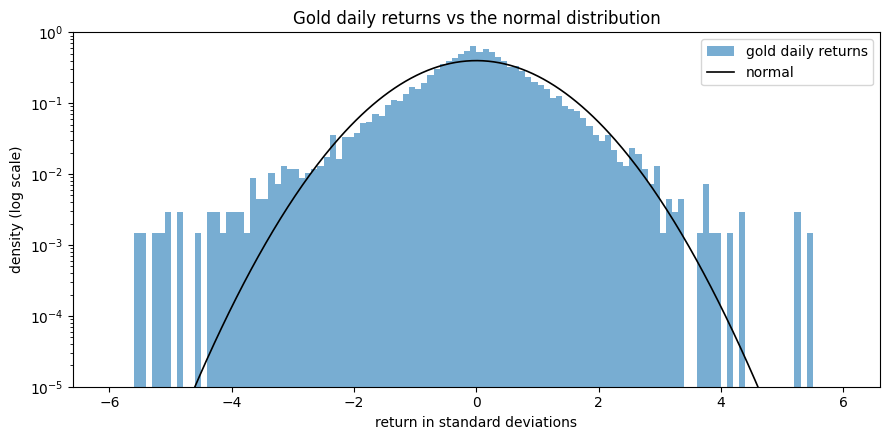

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.linspace(-6, 6, 400)
ax.hist(z, bins=120, range=(-6, 6), density=True, alpha=0.6, label="gold daily returns")
ax.plot(x, stats.norm.pdf(x), color="k", lw=1.2, label="normal")
ax.set_yscale("log"); ax.set_ylim(1e-5, 1)
ax.set_xlabel("return in standard deviations"); ax.set_ylabel("density (log scale)")
ax.set_title("Gold daily returns vs the normal distribution"); ax.legend()
plt.tight_layout(); plt.savefig(ROOT / "images" / "gold-returns-hist.png", dpi=130); plt.show()

روی مقیاس لگاریتمی، دم‌های واقعی خیلی بالاتر از منحنی نرمال‌اند. **روزهای بیش از ۴ انحراف معیار حدود ۶۵ برابر بیشتر از مدل نرمال** رخ داده‌اند.

> قاعده: مدلی که بازده را نرمال فرض کند، ریسک روزهای بد را به‌شدت کم برآورد می‌کند.

## ۲. خوشه‌ای شدن نوسان

اگر نوسان خوشه‌ای باشد، بزرگیِ بازده امروز (نه جهتش) باید با بزرگیِ بازده دیروز همبسته باشد. خودهمبستگی را برای سه چیز می‌سنجیم: خود بازده، قدر مطلق بازده و مربع بازده.

In [5]:
lags = [1, 5, 10, 20, 60]
ac = pd.DataFrame({
    "return": [r.autocorr(l) for l in lags],
    "abs return": [r.abs().autocorr(l) for l in lags],
    "squared return": [(r ** 2).autocorr(l) for l in lags],
}, index=[f"lag {l}" for l in lags]).round(3)
ac

,return,abs return,squared return
lag 1,-0.010,0.119,0.122
lag 5,-0.005,0.148,0.082
lag 10,0.000,0.125,0.062
lag 20,-0.005,0.134,0.063
lag 60,-0.015,0.061,0.041


- **خود بازده** تقریباً صفر است: جهت بازده امروز چیزی درباره فردا نمی‌گوید.
- **قدر مطلق بازده** تا ۶۰ روز بعد هم همبستگی مثبت دارد. نوسان «به‌یاد می‌ماند».

حالا نوسان ۲۱ روزه (سالانه‌شده) را در طول زمان ببینیم:

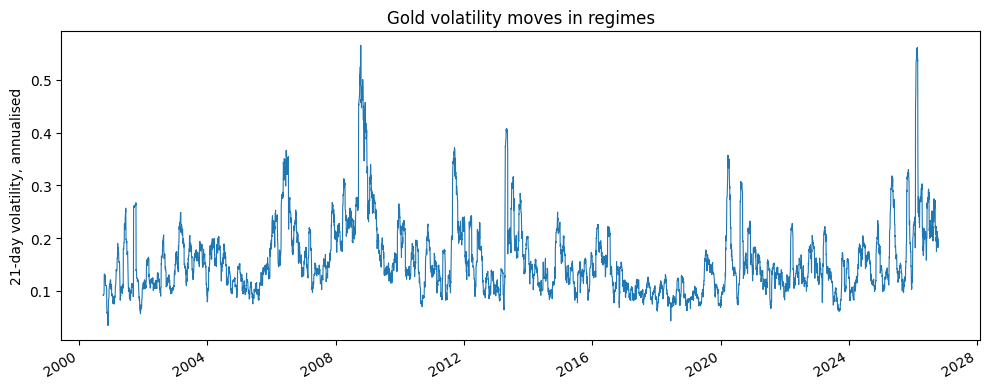

5% / 50% / 95% quantiles: {0.05: 0.084, 0.5: 0.141, 0.95: 0.284}
max 56.5% on 2008-10-13, min 3.5% on 2000-11-24
correlation of this month's vol with next month's: 0.58


In [6]:
vol = r.rolling(21).std() * np.sqrt(252)
fig, ax = plt.subplots(figsize=(10, 4))
vol.plot(ax=ax, lw=0.8)
ax.set_ylabel("21-day volatility, annualised"); ax.set_xlabel("")
ax.set_title("Gold volatility moves in regimes")
plt.tight_layout(); plt.savefig(ROOT / "images" / "gold-returns-vol.png", dpi=130); plt.show()
print("5% / 50% / 95% quantiles:", vol.quantile([.05, .5, .95]).round(3).to_dict())
print(f"max {vol.max():.1%} on {vol.idxmax().date()}, min {vol.min():.1%} on {vol.idxmin().date()}")
v = vol.dropna()
print("correlation of this month's vol with next month's:", round(v.corr(v.shift(-21)), 2))

نوسان بین حدود ۸٪ (صدک ۵) و ۲۸٪ (صدک ۹۵) جابه‌جا می‌شود و اوجش در ۲۰۰۸-۱۰ به ۵۶٪ رسید. همبستگی نوسان این ماه با ماه بعد حدود ۰٫۶ است.

## ۳. اگر نوسان را کنترل کنیم، دم‌ها نرمال می‌شوند؟

یک فکر طبیعی: دم‌های پهن فقط به‌خاطر این است که نوسان عوض می‌شود. اگر هر بازده را بر نوسان همان زمان تقسیم کنیم، شاید نرمال شود. نوسان را با میانگین متحرک نمایی (EWMA، λ = 0٫۹۴) از بازده‌های **قبلی** برآورد می‌کنیم. `shift(1)` مهم است: اگر نوسان امروز را از خود بازده امروز بسازیم، به آینده نگاه کرده‌ایم.

In [7]:
lam = 0.94
sigma = np.sqrt((r_all ** 2).ewm(alpha=1 - lam, adjust=False).mean()).shift(1)   # uses returns up to yesterday only
zs = (r_all / sigma)[START:]
zs = (zs - zs.mean()) / zs.std()

print(f"excess kurtosis: raw {stats.kurtosis(r):.2f} -> standardised {stats.kurtosis(zs):.2f}")
print(f"autocorrelation of |z| at lag 1/5/20: {[round(zs.abs().autocorr(l), 3) for l in (1, 5, 20)]}")
rows = []
for k in (3, 4):
    rows.append({"threshold": f"{k} sigma", "raw": int((z.abs() > k).sum()), "standardised": int((zs.abs() > k).sum()),
                 "expected if normal": round(2 * stats.norm.sf(k) * len(zs), 2)})
pd.DataFrame(rows).set_index("threshold")

excess kurtosis: raw 6.26 -> standardised 3.59
autocorrelation of |z| at lag 1/5/20: [np.float64(-0.038), np.float64(0.017), np.float64(0.016)]


,raw,standardised,expected if normal
threshold,,,
3 sigma,91,72,18.44
4 sigma,28,22,0.43


- خوشه‌ای شدن **حذف شد**: خودهمبستگی قدر مطلق بازده‌های استانداردشده تقریباً صفر است.
- کشیدگی از حدود ۶٫۳ به حدود ۳٫۶ کم شد، یعنی حدود **۴۰٪ از کشیدگی** به تغییر نوسان مربوط بود.
- ولی دم‌ها **هنوز پهن‌اند**: روزهای بیش از ۴ انحراف معیار حدود ۵۰ برابر مدل نرمال است. پس بقیه از خود شوک‌های بزرگ می‌آید؛ علتش را این‌جا بررسی نکرده‌ایم.

## ۴. در دوره‌های مختلف چه فرقی دارد؟

In [8]:
eras = [("1980-1999 (single source, one price a day)", "1980", "1999"), ("2000-09 to 2009", START, "2009"),
        ("2010-2019", "2010", "2019"), ("2020-2026", "2020", "2026")]
pd.DataFrame({
    label: {"days": len(r_all[a:b]), "annualised vol": r_all[a:b].std() * np.sqrt(252), "excess kurtosis": stats.kurtosis(r_all[a:b])}
    for label, a, b in eras
}).T.round(3)

,days,annualised vol,excess kurtosis
"1980-1999 (single source, one price a day)",5161.0,0.199,15.587
2000-09 to 2009,2429.0,0.187,5.733
2010-2019,2603.0,0.151,5.865
2020-2026,1798.0,0.178,6.451


نوسان سالانه در هر دهه بین ۱۵٪ و ۲۰٪ است و کشیدگی اضافه همیشه بالای ۵. دوره ۱۹۸۰ تا ۱۹۹۹ بیشترین کشیدگی (حدود ۱۵) را دارد، ولی آن‌جا فقط یک منبع و یک قیمت در روز داریم و جهش‌های بزرگ ۱۹۸۰ هم هست؛ به همین دلیل تحلیل اصلی از ۲۰۰۰ شروع شد.

## ۵. محدودیت‌ها

۱. **منبع داده:** TGJU غیررسمی است. ۲۰۰۰ به بعد با آتی COMEX مقایسه شد (همبستگی بازده روزانه حدود ۰٫۹؛ از ۲۶ روز بالای ۴ انحراف معیار، تقریباً ۹۶٪ در Yahoo هم با همان علامت و بزرگی‌ای دست‌کم نصف دیده شد). ولی مثلاً ۲۰۰۸-۱۰-۱۰ در TGJU افت ۷٪ است و در Yahoo ۳٫۲٪؛ تفاوت ساعت بسته‌شدن.
۲. **آتی، spot نیست:** بازده روزانه کمی فرق دارد و بعضی روزهای بزرگ ممکن است در یکی بزرگ‌تر باشد.
۳. **EWMA ساده است.** مدل‌های پیچیده‌تر مثل GARCH را امتحان نکرده‌ایم؛ اینجا فقط می‌خواستیم بگوییم خوشه‌ای شدن واقعی است.
۴. **این توصیف گذشته است.** نمی‌گوید فردا چه اتفاقی می‌افتد.

## جمع‌بندی

- بازده روزانه طلا **نرمال نیست**: روزهای بیش از ۴ انحراف معیار حدود ۶۵ برابر مدل نرمال رخ داده‌اند.
- **نوسان خوشه‌ای است** و ماه‌ها به‌یاد می‌ماند، ولی جهت بازده تقریباً غیرقابل‌پیش‌بینی است.
- کنترل نوسان بخشی از کشیدگی را توضیح می‌دهد (حدود ۴۰٪)، نه همه‌اش را.
- نتیجه برای مدیریت ریسک: ریسک را با نوسان **امروز** بسنج، نه با یک انحراف معیار ثابت، و برای روزهای خیلی بد فرض نرمال نگیر.

**گام بعدی:** رابطه طلا با دلار و نرخ بهره، و دام همبستگی کاذب.